# Question 6 — Social Media Usage and Quality-of-Life Characteristics

**Research question:** Is there a relationship between social-media usage characteristics and students' quality-of-life characteristics?

This notebook examines the relationship between social-media usage and two behavioral quality-of-life measures:

- `Study_Hours`
- `Physical_Activity_Hours`

Numerical usage characteristics are examined using Pearson and Spearman correlations, while platform and purpose of use are examined through comparisons between groups.

The analysis identifies statistical associations but does not establish causality.

## 0. Setup and Data Loading

In [1]:
import os
import warnings

warnings.filterwarnings("ignore")

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
# Reproducibility
RANDOM_STATE = 42


# Plotting configuration
sns.set_theme(
    style="whitegrid",
    palette="muted",
    font_scale=1.1
)

plt.rcParams["figure.dpi"] = 110
plt.rcParams["figure.figsize"] = (9, 5)


# Cleaned dataset created by the first data-exploration notebook
DATA_PATH = "../dataset/student_social_media_cleaned.csv"

if not os.path.exists(DATA_PATH):
    raise FileNotFoundError(
        f"{DATA_PATH} was not found. "
        "Run data_exploration/"
        "01_data_overview_and_distributions.ipynb first."
    )

df = pd.read_csv(DATA_PATH)

print("Dataset shape:", df.shape)
df.head()

Dataset shape: (4998, 13)


,Age,Gender,Country,Academic_Level,Most_Used_Platform,Purpose_Of_Use,Avg_Daily_Usage_Hours,Daily_Unlocks,Study_Hours,Physical_Activity_Hours,Sleep_Hours_Per_Night,Stress_Level,Mental_Health_Score
0,21,Male,Other,Undergraduate,Facebook,Networking,4.0,134,4.5,2.2,6.7,Medium,6.8
1,23,Female,Other,Graduate,LinkedIn,Education,1.6,73,7.0,2.4,8.6,Low,7.6
2,22,Male,Canada,Undergraduate,Instagram,Entertainment,4.6,166,4.0,1.8,6.7,Medium,7.0
3,18,Male,Other,High School,Snapchat,Entertainment,7.0,220,1.0,1.7,5.4,Very High,5.3
4,24,Female,Other,Graduate,Facebook,Networking,7.5,237,1.0,1.1,5.0,Very High,4.4


## 1. Correlation Between Social-Media Usage and Quality-of-Life Measures

In [2]:
from scipy.stats import pearsonr, spearmanr

usage_features = [
    "Avg_Daily_Usage_Hours",
    "Daily_Unlocks"
]

quality_of_life_features = [
    "Study_Hours",
    "Physical_Activity_Hours"
]

results = []

for usage_feature in usage_features:
    for quality_feature in quality_of_life_features:

        # Keep only complete observations for the current pair
        pair_data = df[
            [usage_feature, quality_feature]
        ].dropna()

        pearson_r, pearson_p = pearsonr(
            pair_data[usage_feature],
            pair_data[quality_feature]
        )

        spearman_r, spearman_p = spearmanr(
            pair_data[usage_feature],
            pair_data[quality_feature]
        )

        results.append({
            "Usage Feature": usage_feature,
            "Quality-of-Life Feature": quality_feature,
            "Pearson Correlation": pearson_r,
            "Pearson p-value": pearson_p,
            "Spearman Correlation": spearman_r,
            "Spearman p-value": spearman_p
        })

correlation_results = pd.DataFrame(results)

display(
    correlation_results.round({
        "Pearson Correlation": 3,
        "Pearson p-value": 4,
        "Spearman Correlation": 3,
        "Spearman p-value": 4
    })
)

,Usage Feature,Quality-of-Life Feature,Pearson Correlation,Pearson p-value,Spearman Correlation,Spearman p-value
0,Avg_Daily_Usage_Hours,Study_Hours,-0.879,0.0,-0.889,0.0
1,Avg_Daily_Usage_Hours,Physical_Activity_Hours,-0.626,0.0,-0.624,0.0
2,Daily_Unlocks,Study_Hours,-0.853,0.0,-0.864,0.0
3,Daily_Unlocks,Physical_Activity_Hours,-0.603,0.0,-0.599,0.0


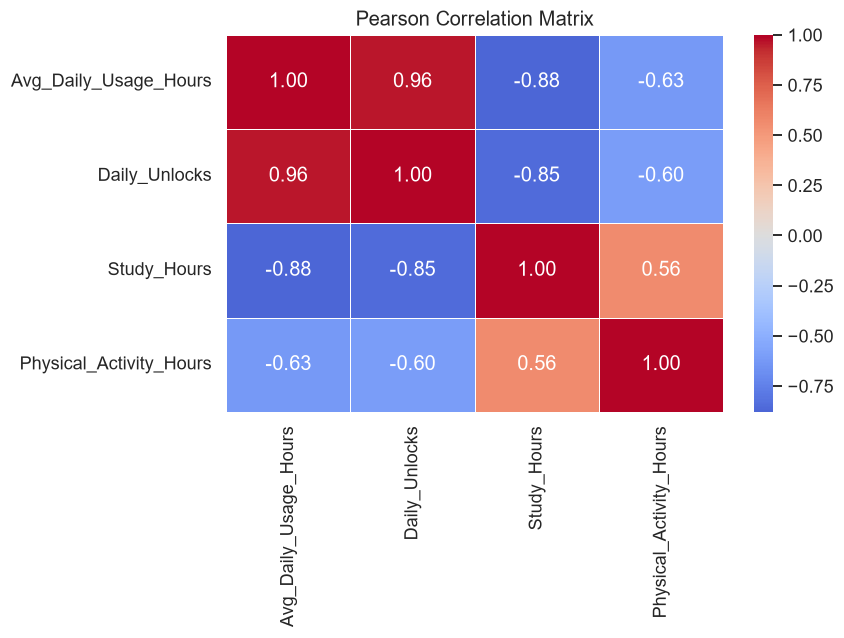

In [3]:
corr_variables = [
    "Avg_Daily_Usage_Hours",
    "Daily_Unlocks",
    "Study_Hours",
    "Physical_Activity_Hours"
]

corr_matrix = df[corr_variables].corr(method="pearson")

plt.figure(figsize=(8, 6))
sns.heatmap(
    corr_matrix,
    annot=True,
    fmt=".2f",
    cmap="coolwarm",
    center=0,
    linewidths=0.5
)

plt.title("Pearson Correlation Matrix")
plt.tight_layout()
plt.show()

The correlation matrix shows that greater social-media usage is associated with fewer study and physical-activity hours, with a stronger relationship observed for study hours.

## 2. Visualizing the Main Relationships

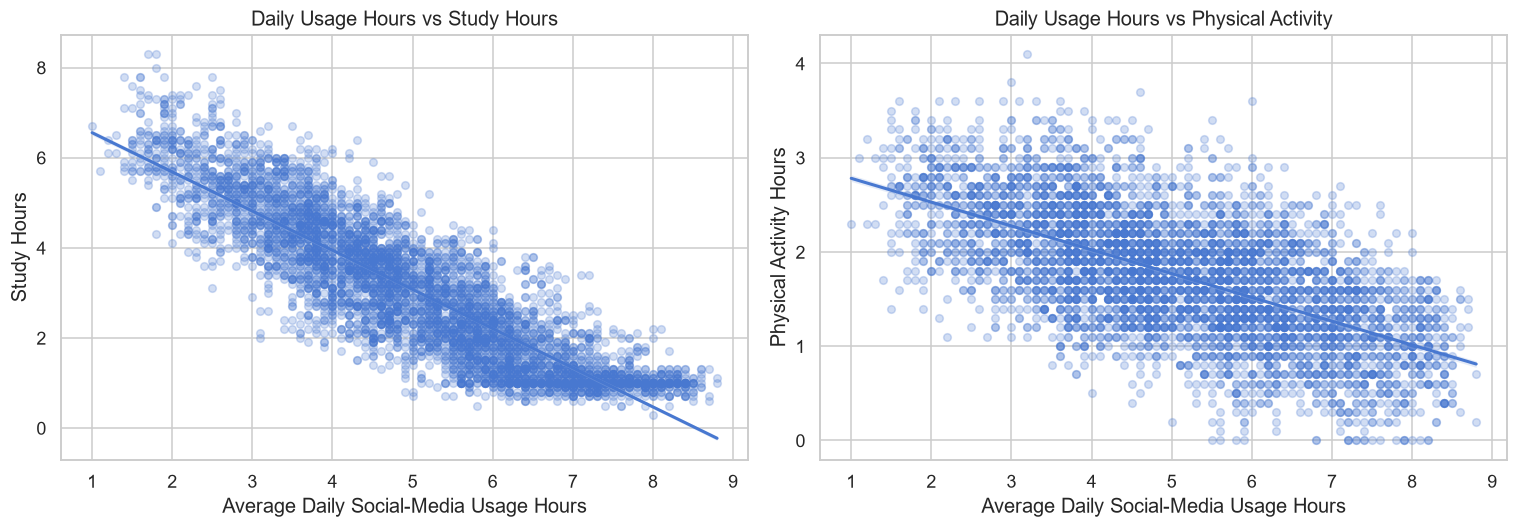

In [4]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

sns.regplot(
    data=df,
    x="Avg_Daily_Usage_Hours",
    y="Study_Hours",
    scatter_kws={"alpha": 0.25, "s": 25},
    line_kws={"linewidth": 2},
    ax=axes[0]
)

axes[0].set_title("Daily Usage Hours vs Study Hours")
axes[0].set_xlabel("Average Daily Social-Media Usage Hours")
axes[0].set_ylabel("Study Hours")


sns.regplot(
    data=df,
    x="Avg_Daily_Usage_Hours",
    y="Physical_Activity_Hours",
    scatter_kws={"alpha": 0.25, "s": 25},
    line_kws={"linewidth": 2},
    ax=axes[1]
)

axes[1].set_title("Daily Usage Hours vs Physical Activity")
axes[1].set_xlabel("Average Daily Social-Media Usage Hours")
axes[1].set_ylabel("Physical Activity Hours")

plt.tight_layout()
plt.show()

Both outcomes decrease as daily social-media usage increases; however, the relationship is stronger and more consistent for study hours, while physical activity shows greater variability between users.

## 3. Quality-of-Life Measures by Platform and Purpose of Use

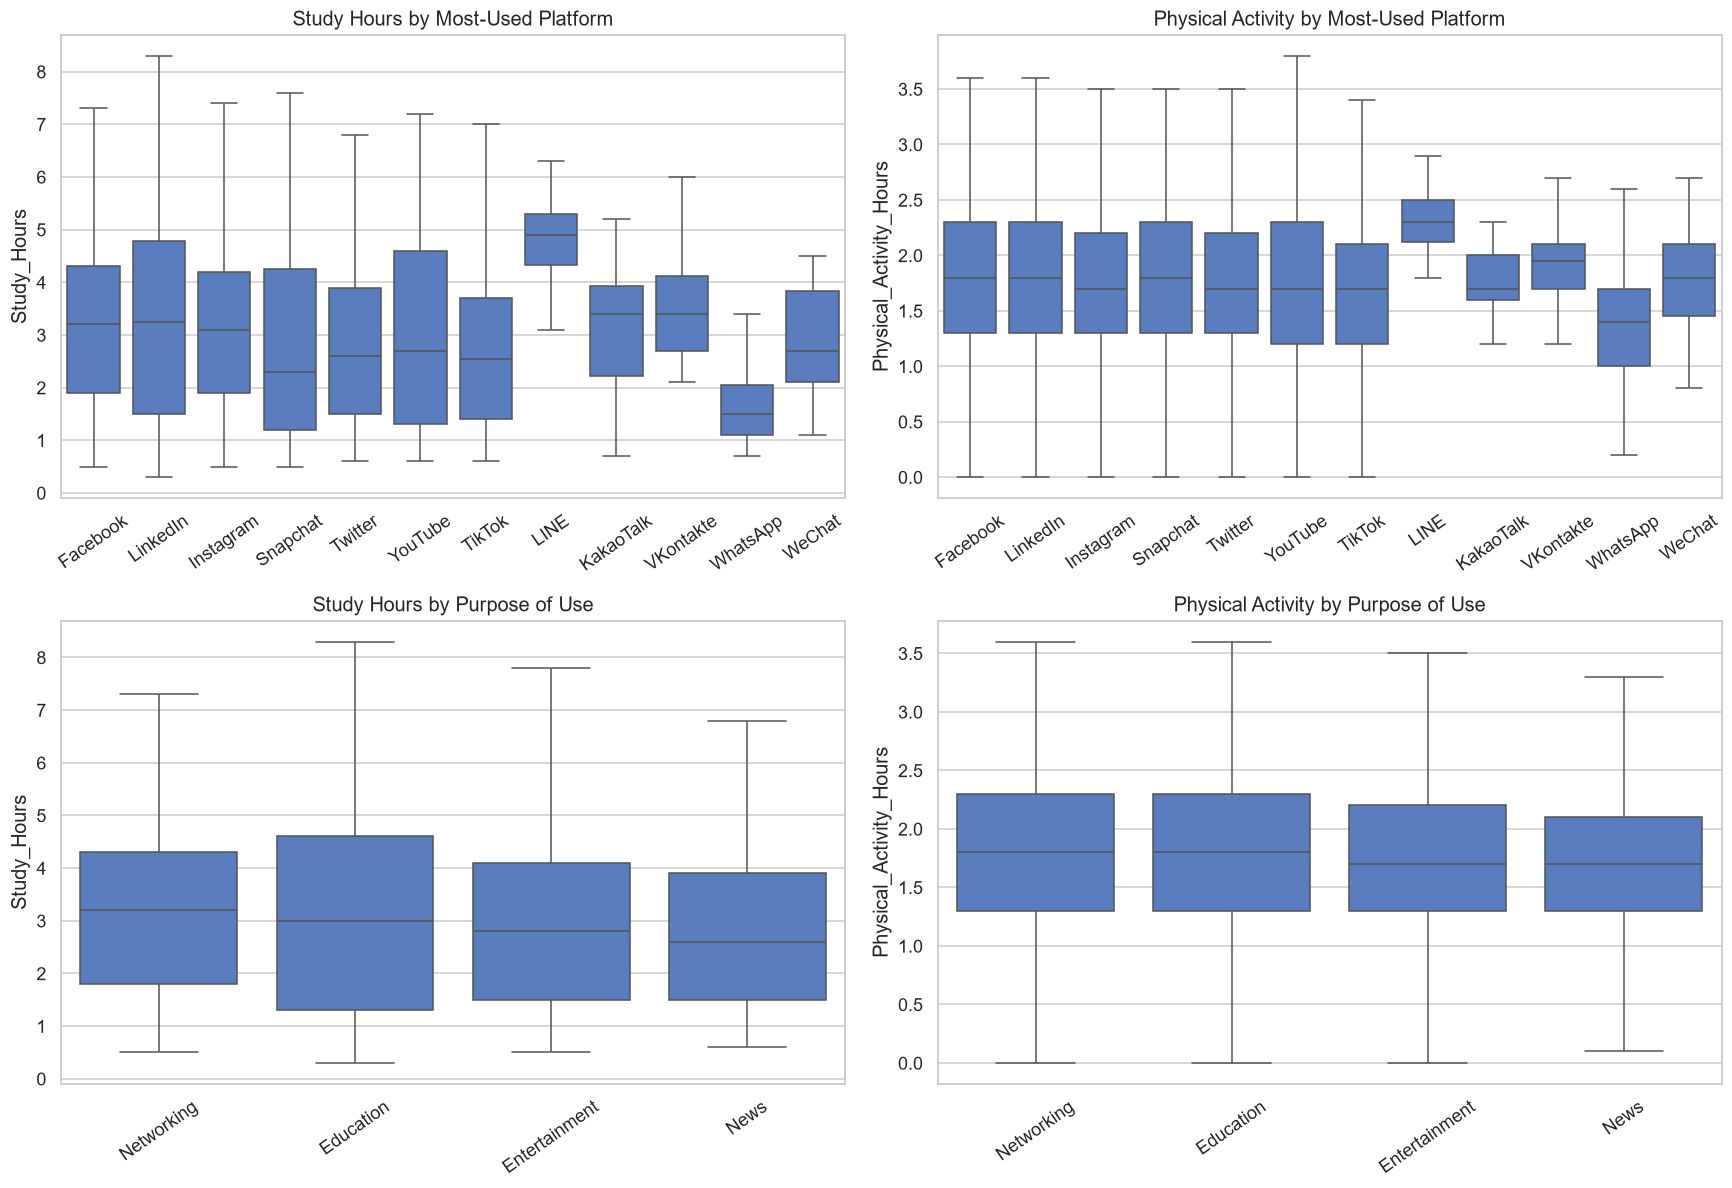

In [5]:
fig, axes = plt.subplots(2, 2, figsize=(16, 11))

sns.boxplot(
    data=df,
    x="Most_Used_Platform",
    y="Study_Hours",
    showfliers=False,
    ax=axes[0, 0]
)
axes[0, 0].set_title("Study Hours by Most-Used Platform")
axes[0, 0].set_xlabel("")
axes[0, 0].tick_params(axis="x", rotation=35)


sns.boxplot(
    data=df,
    x="Most_Used_Platform",
    y="Physical_Activity_Hours",
    showfliers=False,
    ax=axes[0, 1]
)
axes[0, 1].set_title("Physical Activity by Most-Used Platform")
axes[0, 1].set_xlabel("")
axes[0, 1].tick_params(axis="x", rotation=35)


sns.boxplot(
    data=df,
    x="Purpose_Of_Use",
    y="Study_Hours",
    showfliers=False,
    ax=axes[1, 0]
)
axes[1, 0].set_title("Study Hours by Purpose of Use")
axes[1, 0].set_xlabel("")
axes[1, 0].tick_params(axis="x", rotation=35)


sns.boxplot(
    data=df,
    x="Purpose_Of_Use",
    y="Physical_Activity_Hours",
    showfliers=False,
    ax=axes[1, 1]
)
axes[1, 1].set_title("Physical Activity by Purpose of Use")
axes[1, 1].set_xlabel("")
axes[1, 1].tick_params(axis="x", rotation=35)

plt.tight_layout()
plt.show()

Platform differences are more visible for study hours than for physical activity, while the purpose-of-use groups largely overlap, suggesting that usage intensity may be more informative than the categorical context of use.

## 4. Statistical Comparison Across Usage Categories

The boxplots suggest possible differences between platforms and purposes of use. To determine whether these differences are statistically significant, Kruskal–Wallis tests are performed for each quality-of-life measure.

Because four statistical comparisons are conducted, Holm correction is applied to control for multiple testing. Epsilon-squared is also reported to measure the magnitude of each association.

In [6]:
import numpy as np
import pandas as pd
from scipy.stats import kruskal


# Variables examined in the group comparisons
categorical_features = [
    "Most_Used_Platform",
    "Purpose_Of_Use"
]

quality_of_life_features = [
    "Study_Hours",
    "Physical_Activity_Hours"
]


# Perform the Kruskal-Wallis tests
test_results = []

for usage_feature in categorical_features:
    for quality_feature in quality_of_life_features:

        test_data = df[
            [usage_feature, quality_feature]
        ].dropna()

        groups = [
            group[quality_feature].to_numpy()
            for _, group in test_data.groupby(usage_feature)
            if len(group) > 0
        ]

        h_statistic, p_value = kruskal(*groups)

        number_of_groups = len(groups)
        number_of_observations = len(test_data)

        # Epsilon-squared effect size
        if number_of_observations > number_of_groups:
            epsilon_squared = (
                h_statistic
                - number_of_groups
                + 1
            ) / (
                number_of_observations
                - number_of_groups
            )

            epsilon_squared = max(0, epsilon_squared)
        else:
            epsilon_squared = np.nan

        test_results.append({
            "Usage Feature": usage_feature,
            "Quality-of-Life Feature": quality_feature,
            "Number of Groups": number_of_groups,
            "Kruskal-Wallis H": h_statistic,
            "p-value": p_value,
            "Epsilon Squared": epsilon_squared
        })


group_test_results = pd.DataFrame(test_results)


# Holm correction for multiple comparisons
def holm_adjustment(p_values):
    p_values = np.asarray(p_values, dtype=float)
    number_of_tests = len(p_values)

    sorted_indices = np.argsort(p_values)
    sorted_p_values = p_values[sorted_indices]

    adjusted_sorted = np.zeros(number_of_tests)
    previous_adjusted_value = 0

    for index, p_value in enumerate(sorted_p_values):
        adjusted_value = (
            number_of_tests - index
        ) * p_value

        adjusted_value = max(
            adjusted_value,
            previous_adjusted_value
        )

        adjusted_value = min(adjusted_value, 1)

        adjusted_sorted[index] = adjusted_value
        previous_adjusted_value = adjusted_value

    adjusted_p_values = np.zeros(number_of_tests)
    adjusted_p_values[sorted_indices] = adjusted_sorted

    return adjusted_p_values


group_test_results["Adjusted p-value"] = holm_adjustment(
    group_test_results["p-value"]
)

group_test_results["Significant"] = (
    group_test_results["Adjusted p-value"] < 0.05
)


# Create a formatted table for display
display_results = group_test_results.copy()

display_results["Kruskal-Wallis H"] = (
    display_results["Kruskal-Wallis H"].round(3)
)

display_results["Epsilon Squared"] = (
    display_results["Epsilon Squared"].round(4)
)

display_results["p-value"] = (
    display_results["p-value"]
    .map(lambda value: f"{value:.3e}")
)

display_results["Adjusted p-value"] = (
    display_results["Adjusted p-value"]
    .map(lambda value: f"{value:.3e}")
)

display(display_results)

,Usage Feature,Quality-of-Life Feature,Number of Groups,Kruskal-Wallis H,p-value,Epsilon Squared,Adjusted p-value,Significant
0,Most_Used_Platform,Study_Hours,12,242.462,1.056e-45,0.0464,4.224e-45,True
1,Most_Used_Platform,Physical_Activity_Hours,12,136.125,9.983e-24,0.0251,2.995e-23,True
2,Purpose_Of_Use,Study_Hours,4,16.063,1.101e-03,0.0026,2.201e-03,True
3,Purpose_Of_Use,Physical_Activity_Hours,4,6.488,9.015e-02,0.0007,9.015e-02,False


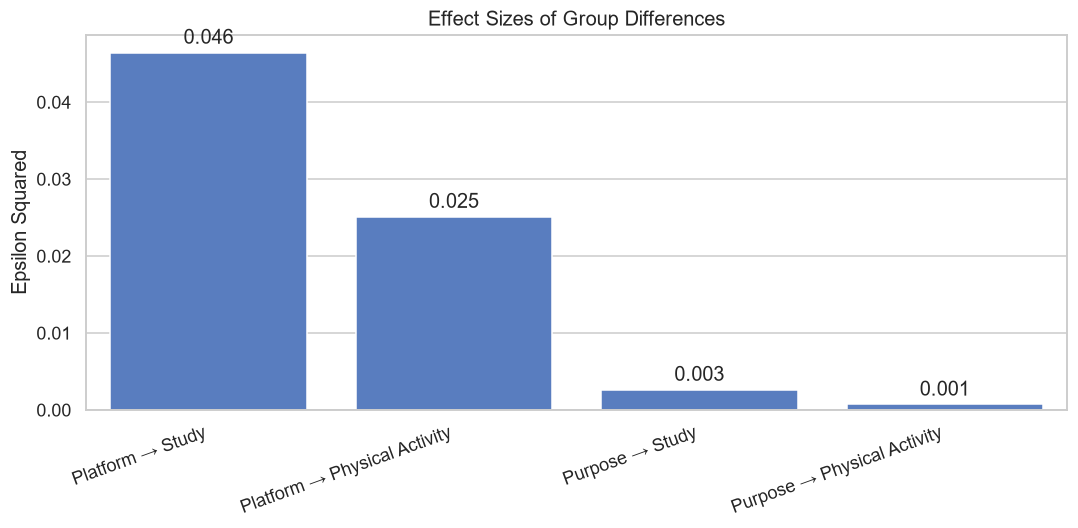

In [7]:
plot_df = group_test_results.copy()

plot_df["Comparison"] = [
    "Platform → Study",
    "Platform → Physical Activity",
    "Purpose → Study",
    "Purpose → Physical Activity"
]

plt.figure(figsize=(10, 5))

ax = sns.barplot(
    data=plot_df,
    x="Comparison",
    y="Epsilon Squared"
)

ax.bar_label(
    ax.containers[0],
    fmt="%.3f",
    padding=3
)

plt.title("Effect Sizes of Group Differences")
plt.xlabel("")
plt.ylabel("Epsilon Squared")
plt.xticks(rotation=20, ha="right")
plt.tight_layout()
plt.show()

Platform is more strongly associated with both quality-of-life measures than purpose of use, although all effect sizes are small. These group comparisons are unadjusted for usage intensity, so part of the observed platform differences may reflect differences in how intensively each platform is used.

## 5. Conclusions

Higher social-media usage intensity is associated with fewer study hours and fewer physical-activity hours. The relationship is considerably stronger for study hours.

Platform is also associated with both quality-of-life measures, but the observed effect sizes are small. Purpose of use shows only a negligible association with study hours and no significant association with physical activity.

Overall, usage intensity shows stronger associations with the examined quality-of-life measures than platform or purpose of use. However, the categorical comparisons were not adjusted for usage intensity, and the observational design does not allow causal conclusions.